Maximum Power Point Tracking using Cuckoo Search
Best Voltage: 54.7 V
Best Current: 5.96 A
Maximum Power: 326.01 W


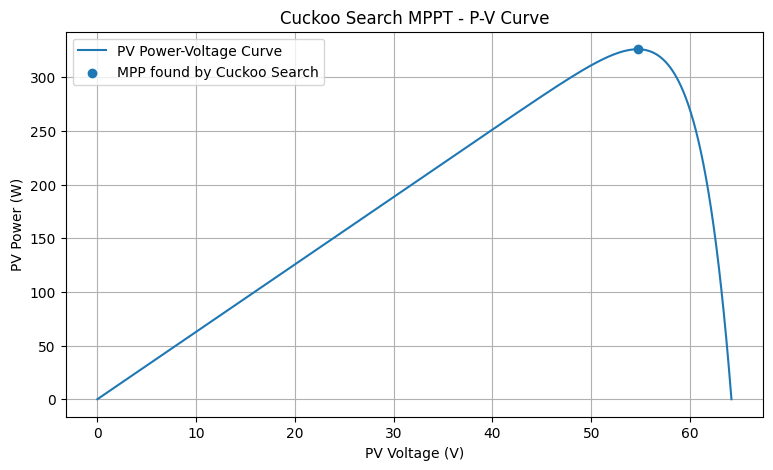

In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt

# Solar panel specifications
Voc = 64.2
Vmp = 54.7
Imp = 5.96

# Simplified solar panel model
n = 18.5719
Isc = Imp / (1 - (Vmp / Voc) ** n)

# Calculate current
def current(v):
    return Isc * (1 - (v / Voc) ** n)

# Calculate power
def power(v):
    return v * current(v)


# Cuckoo Search parameters
nests = 25
iterations = 100
pa = 0.25

# Generate random nests (voltages)
population = [random.uniform(0, Voc) for i in range(nests)]

# Cuckoo Search
for iteration in range(iterations):

    for i in range(nests):

        # Levy flight (random jump)
        step = random.choice([-1, 1]) * 0.5 * (random.paretovariate(1.5) - 1)

        new_voltage = population[i] + step

        # Keep voltage within limits
        new_voltage = max(0, min(Voc, new_voltage))

        # Select a random nest
        j = random.randint(0, nests - 1)

        # Replace if new power is better
        if power(new_voltage) > power(population[j]):
            population[j] = new_voltage

    # Abandon worst nests
    population.sort(key=power, reverse=True)

    for i in range(int(pa * nests)):
        population[-(i + 1)] = random.uniform(0, Voc)


# Find best voltage
best_voltage = max(population, key=power)

best_current = current(best_voltage)
best_power = power(best_voltage)

print("Maximum Power Point Tracking using Cuckoo Search")
print("Best Voltage:", round(best_voltage, 2), "V")
print("Best Current:", round(best_current, 2), "A")
print("Maximum Power:", round(best_power, 2), "W")

# Plot the PV Power-Voltage graph
voltages = np.linspace(0, Voc, 500)
powers = [power(v) for v in voltages]

plt.figure(figsize=(9, 5))
plt.plot(voltages, powers, label="PV Power-Voltage Curve")

plt.scatter(best_voltage, best_power,
            label="MPP found by Cuckoo Search")

plt.xlabel("PV Voltage (V)")
plt.ylabel("PV Power (W)")
plt.title("Cuckoo Search MPPT - P-V Curve")
plt.grid(True)
plt.legend()
plt.show()
